# Flight Delay Analysis
## Exploratory Data Analysis
* **Goal:** Understand the structure, quality and charachteristics of the dataset.

In [1]:
# Import libaries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
# Safe data loading with try / except
try:
    df = pd.read_csv('../data/flight_data_2024.csv')
    print('Data Load successfully')
except FileNotFoundError:
    print('File not Found - check Path')
except Exception as e:
    print('Other Error occurr - check {e}')

/var/folders/q8/v6_548714bg4cjmlh_2vhkxh0000gn/T/ipykernel_37903/1565152846.py:3: DtypeWarning: Columns (24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/flight_data_2024.csv')


Data Load successfully


In [3]:
df.columns[24]

'cancellation_code'

**Note**: Column 24 - Cancellation Code needs further inspection

In [4]:
# Check cols and rows
print(f'Cols: {df.shape[0]} -- Rows: {df.shape[1]}')

Cols: 7079081 -- Rows: 35


In [5]:
# Inspection of Dataset
df.describe(include='all')

,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
count,7079081.0,7.079081e+06,7.079081e+06,7.079081e+06,7079081,7079081,7.079080e+06,7079081,7079081,7079081,...,7.079081e+06,7.079080e+06,6.965267e+06,6.965267e+06,7.079081e+06,7.079081e+06,7.079081e+06,7.079081e+06,7.079081e+06,7.079081e+06
unique,NaN,NaN,NaN,NaN,366,15,NaN,348,342,52,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,2024-12-01,WN,NaN,ATL,"Chicago, IL",Texas,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,21764,1419419,NaN,341910,359685,751839,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2024.0,6.584868e+00,1.578445e+01,3.981945e+00,NaN,NaN,2.504623e+03,NaN,NaN,NaN,...,2.471931e-03,1.467665e+02,1.412151e+02,1.149997e+02,8.339062e+02,5.060440e+00,8.752369e-01,2.771828e+00,2.541686e-02,5.929302e+00
std,0.0,3.396806e+00,8.786433e+00,2.012279e+00,NaN,NaN,1.652253e+03,NaN,NaN,NaN,...,4.965703e-02,7.238692e+01,7.230781e+01,7.036955e+01,5.962536e+02,3.572703e+01,1.542974e+01,1.546485e+01,1.422602e+00,3.106135e+01
min,2024.0,1.000000e+00,1.000000e+00,1.000000e+00,NaN,NaN,1.000000e+00,NaN,NaN,NaN,...,0.000000e+00,-1.600000e+02,1.500000e+01,5.000000e+00,1.100000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2024.0,4.000000e+00,8.000000e+00,2.000000e+00,NaN,NaN,1.151000e+03,NaN,NaN,NaN,...,0.000000e+00,9.300000e+01,8.800000e+01,6.300000e+01,3.990000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2024.0,7.000000e+00,1.600000e+01,4.000000e+00,NaN,NaN,2.227000e+03,NaN,NaN,NaN,...,0.000000e+00,1.300000e+02,1.250000e+02,9.800000e+01,6.800000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2024.0,1.000000e+01,2.300000e+01,6.000000e+00,NaN,NaN,3.717000e+03,NaN,NaN,NaN,...,0.000000e+00,1.770000e+02,1.720000e+02,1.450000e+02,1.069000e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


In [6]:
df.head()

,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2024,1,1,1,2024-01-01,9E,4814.0,JFK,"New York, NY",New York,...,0,136.0,122.0,84.0,509.0,0,0,0,0,0
1,2024,1,1,1,2024-01-01,9E,4815.0,MSP,"Minneapolis, MN",Minnesota,...,0,130.0,114.0,88.0,622.0,0,0,0,0,0
2,2024,1,1,1,2024-01-01,9E,4817.0,JFK,"New York, NY",New York,...,0,106.0,90.0,61.0,288.0,0,0,0,0,0
3,2024,1,1,1,2024-01-01,9E,4817.0,RIC,"Richmond, VA",Virginia,...,0,111.0,76.0,51.0,288.0,0,0,0,0,0
4,2024,1,1,1,2024-01-01,9E,4818.0,DTW,"Detroit, MI",Michigan,...,0,79.0,70.0,45.0,237.0,0,0,0,0,0


In [7]:
# Check missing values
df.isna().sum()

year                         0
month                        0
day_of_month                 0
day_of_week                  0
fl_date                      0
op_unique_carrier            0
op_carrier_fl_num            1
origin                       0
origin_city_name             0
origin_state_nm              0
dest                         0
dest_city_name               0
dest_state_nm                0
crs_dep_time                 0
dep_time                 92659
dep_delay                92970
taxi_out                 95734
wheels_off               95734
wheels_on                97856
taxi_in                  97856
crs_arr_time                 0
arr_time                 97854
arr_delay               113814
cancelled                    0
cancellation_code      6982766
diverted                     0
crs_elapsed_time             1
actual_elapsed_time     113814
air_time                113814
distance                     0
carrier_delay                0
weather_delay                0
nas_dela

**Note:** A lot of missing values, especially almost all cancellation codes value are missing which should be handeld in Feature Engineering

In [8]:
df[['year', 'month', 'day_of_month', 'day_of_week']].dtypes
df[['year', 'month', 'day_of_month', 'day_of_week']].head()

,year,month,day_of_month,day_of_week
0,2024,1,1,1
1,2024,1,1,1
2,2024,1,1,1
3,2024,1,1,1
4,2024,1,1,1


In [9]:
# Convert into pandas daytime
df['date'] = pd.to_datetime({
    'year': df['year'],
    'month': df['month'],
    'day': df['day_of_month'] 
})

In [10]:
df['year'].min()

2024

In [11]:
df['date'].head()

0   2024-01-01
1   2024-01-01
2   2024-01-01
3   2024-01-01
4   2024-01-01
Name: date, dtype: datetime64[ns]

In [12]:
top_five_airports_dep = df.groupby('origin')['year'].size().sort_values(ascending=False).head(5)

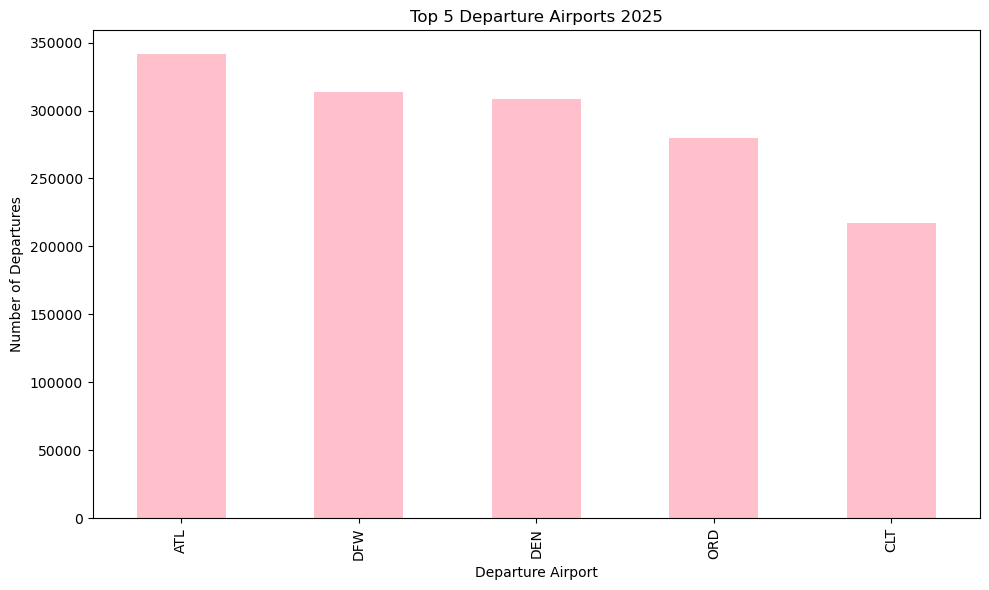

In [13]:
plt.figure(figsize=(10,6))
top_five_airports_dep.plot(kind='bar', color='pink')
plt.title('Top 5 Departure Airports 2025')
plt.xlabel('Departure Airport')
plt.ylabel('Number of Departures')

plt.tight_layout()
plt.show()

**Note:** The Top 5 Departure Airports in 2024 with the hightest numbers of Departures are:

- Atlanta (ATL) with 341910
- Dallas (DFW) with 313582
- Denver (DEN) with 308645
- Chicago O'Hare (ORD) with 280052
- Charlotte Douglas (CLT) with 217574

In [20]:
top_five_airports_dest = df.groupby('dest')['year'].count().sort_values(ascending=False).head(5)
top_five_airports_dest

dest
ATL    341844
DFW    313568
DEN    308609
ORD    280009
CLT    217545
Name: year, dtype: int64

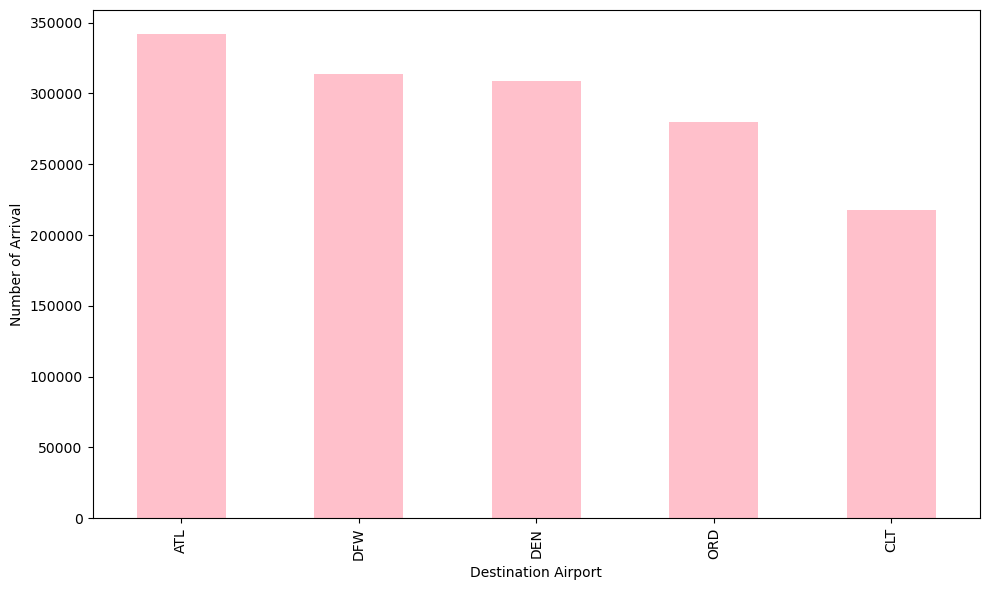

In [16]:
plt.figure(figsize=(10,6))
top_five_airports_dest.plot(kind='bar', color='pink')
plt.title('')
plt.xlabel('Destination Airport')
plt.ylabel('Number of Arrival')

plt.tight_layout()
plt.show()

**Note:** Top 5 Destination Airports are also:

- Atlanta (ATL) with 341844
- Dallas (DFW) with 313568
- Denver (DEN) with 308609
- Chicago O'Hare (ORD) with 280009
- Charlotte Douglas (CLT) with 217574

In [21]:
print(top_five_airports_dep - top_five_airports_dest)

origin
ATL    66
DFW    14
DEN    36
ORD    43
CLT    29
Name: year, dtype: int64
